## Imports and downloads

In [21]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter

import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

nltk.download("punkt", quiet=True)
nltk.download("punkt_tab", quiet=True)
nltk.download("stopwords", quiet=True)
nltk.download("wordnet", quiet=True)

True

## Step 1: Load the dataset

In [22]:
df = pd.read_csv("IMDB Dataset.csv")
print("Shape:", df.shape)
print(df["sentiment"].value_counts())
df.head()

Shape: (50000, 2)
sentiment
positive    25000
negative    25000
Name: count, dtype: int64


,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


## Step 2: Text preprocessing

In [ ]:
def clean_text(text):
    text = text.lower()                      
    text = re.sub(r"<.*?>", " ", text)        
    text = re.sub(r"[^a-z\s]", " ", text)     
    text = re.sub(r"\s+", " ", text).strip()  
    return text

print(clean_text("WOW!!! This movie was GREAT <br /> 10/10"))

wow this movie was great


In [23]:
# Stopwords, but keep the negation words because they change the sentiment
keep = {"not", "no", "nor", "don", "didn", "doesn", "isn", "wasn",
        "aren", "weren", "couldn", "wouldn", "shouldn", "hasn",
        "haven", "hadn", "won", "mustn", "needn", "shan", "ain", "mightn"}
stop_words = set(stopwords.words("english")) - keep

lemmatizer = WordNetLemmatizer()

def preprocess(text):
    text = clean_text(text)                                  
    tokens = word_tokenize(text)                             
    tokens = [w for w in tokens if w not in stop_words]      
    tokens = [lemmatizer.lemmatize(w) for w in tokens]       
    return " ".join(tokens)

In [24]:
sample = "The movies were NOT good, and the actors weren't trying!"
print("Original  :", sample)
print("Cleaned   :", clean_text(sample))
print("Tokens    :", word_tokenize(clean_text(sample)))
print("Final     :", preprocess(sample))

Original  : The movies were NOT good, and the actors weren't trying!
Cleaned   : the movies were not good and the actors weren t trying
Tokens    : ['the', 'movies', 'were', 'not', 'good', 'and', 'the', 'actors', 'weren', 't', 'trying']
Final     : movie not good actor weren trying


In [25]:
df["clean_review"] = df["review"].apply(preprocess)

print("BEFORE:", df["review"][1][:150])
print("AFTER :", df["clean_review"][1][:150])

BEFORE: A wonderful little production. <br /><br />The filming technique is very unassuming- very old-time-BBC fashion and gives a comforting, and sometimes d
AFTER : wonderful little production filming technique unassuming old time bbc fashion give comforting sometimes discomforting sense realism entire piece actor


## Step 3: Train/test split and TF-IDF

In [26]:
X = df["clean_review"]
y = df["sentiment"].map({"positive": 1, "negative": 0})

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("Train size:", len(X_train), "| Test size:", len(X_test))

tfidf = TfidfVectorizer(max_features=20000, ngram_range=(1, 2))
X_train_vec = tfidf.fit_transform(X_train)  
X_test_vec = tfidf.transform(X_test)         
print("TF-IDF shape (train):", X_train_vec.shape)
print("TF-IDF shape (test) :", X_test_vec.shape)

Train size: 40000 | Test size: 10000
TF-IDF shape (train): (40000, 20000)
TF-IDF shape (test) : (10000, 20000)


## Step 4: Train Logistic Regression and evaluate

In [27]:
model = LogisticRegression(max_iter=1000)
model.fit(X_train_vec, y_train)
print("Training finished")

Training finished


In [28]:
y_pred = model.predict(X_test_vec)
lr_acc = accuracy_score(y_test, y_pred)

print("Logistic Regression Accuracy:", round(lr_acc, 4))
print()
print(classification_report(y_test, y_pred, target_names=["negative", "positive"]))
print("Confusion matrix:")
print(confusion_matrix(y_test, y_pred))

Logistic Regression Accuracy: 0.9016

              precision    recall  f1-score   support

    negative       0.91      0.89      0.90      5000
    positive       0.89      0.91      0.90      5000

    accuracy                           0.90     10000
   macro avg       0.90      0.90      0.90     10000
weighted avg       0.90      0.90      0.90     10000

Confusion matrix:
[[4463  537]
 [ 447 4553]]


In [30]:
def predict_sentiment(text):
    vec = tfidf.transform([preprocess(text)])
    prob = model.predict_proba(vec)[0][1]          # probability of positive
    label = "positive" if prob >= 0.5 else "negative"
    return label, round(prob, 3)

tests = [
    "This movie was absolutely amazing, I loved every minute",
    "Terrible film, a complete waste of time",
    "This movie was not good at all",
    "The plot was okay but nothing special",
]
for t in tests:
    print(predict_sentiment(t), "<-", t)

('positive', np.float64(0.839)) <- This movie was absolutely amazing, I loved every minute
('negative', np.float64(0.005)) <- Terrible film, a complete waste of time
('negative', np.float64(0.087)) <- This movie was not good at all
('negative', np.float64(0.027)) <- The plot was okay but nothing special


## Step 5 (Bonus): Most frequent positive and negative words

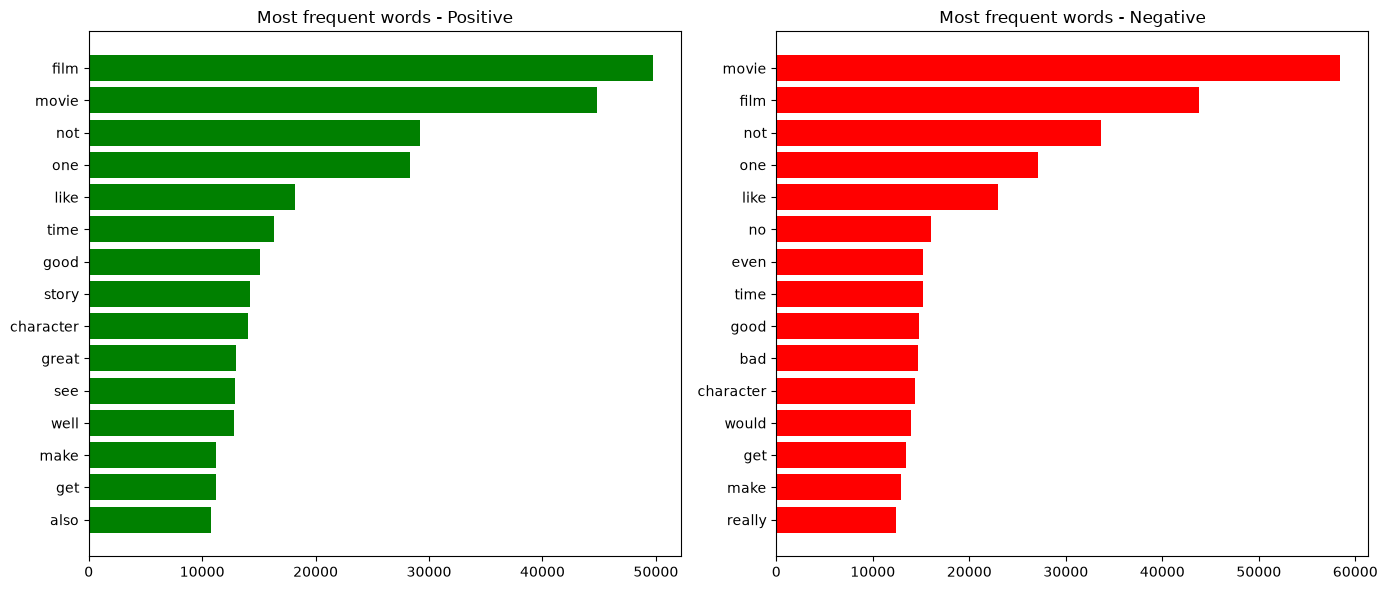

In [31]:
def top_words(series, n=15):
    counter = Counter(" ".join(series).split())
    return counter.most_common(n)

pos_words = top_words(df[df["sentiment"] == "positive"]["clean_review"])
neg_words = top_words(df[df["sentiment"] == "negative"]["clean_review"])

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, words, title, color in [
    (axes[0], pos_words, "Most frequent words - Positive", "green"),
    (axes[1], neg_words, "Most frequent words - Negative", "red"),
]:
    labels, counts = zip(*words)
    ax.barh(labels[::-1], counts[::-1], color=color)
    ax.set_title(title)
plt.tight_layout()
plt.savefig("frequent_words.png", dpi=150, bbox_inches="tight")
plt.show()

## Step 6 (Bonus): Naive Bayes and accuracy comparison

In [34]:
nb = MultinomialNB()
nb.fit(X_train_vec, y_train)
nb_pred = nb.predict(X_test_vec)
nb_acc = accuracy_score(y_test, nb_pred)

print(f"Logistic Regression: {lr_acc:.4f}")
print(f"Naive Bayes:         {nb_acc:.4f}")
print()
print(classification_report(y_test, nb_pred, target_names=["negative", "positive"]))

Logistic Regression: 0.9016
Naive Bayes:         0.8790

              precision    recall  f1-score   support

    negative       0.89      0.86      0.88      5000
    positive       0.87      0.90      0.88      5000

    accuracy                           0.88     10000
   macro avg       0.88      0.88      0.88     10000
weighted avg       0.88      0.88      0.88     10000



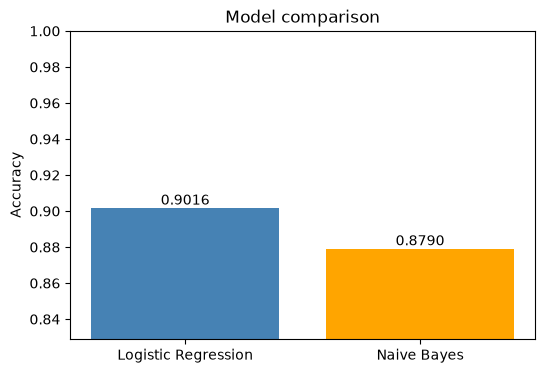

Best model: Logistic Regression (difference: 0.0226)


In [35]:
models = ["Logistic Regression", "Naive Bayes"]
accs = [lr_acc, nb_acc]

plt.figure(figsize=(6, 4))
bars = plt.bar(models, accs, color=["steelblue", "orange"])
plt.ylim(min(accs) - 0.05, 1)
plt.ylabel("Accuracy")
plt.title("Model comparison")
for b, a in zip(bars, accs):
    plt.text(b.get_x() + b.get_width() / 2, a + 0.002, f"{a:.4f}", ha="center")
plt.savefig("model_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

best = models[accs.index(max(accs))]
print(f"Best model: {best} (difference: {abs(lr_acc - nb_acc):.4f})")